# Ridge vs early stopping in MGD: turbulence, with and without redundant statistics

**What MGD does.** Moment Guided Diffusion transports $N$ walkers from Gaussian noise to the data distribution so that, at
every time $t$, the walkers' averages of a set of $r$ statistics $\phi$ (wavelet moments) match those of the
data–noise interpolant. At each time step a *corrector* moves the walkers along $\theta^\top\nabla\phi$, with $\theta$ the
solution of a linear system
$$\hat G\,\theta = b,\qquad \hat G=\tfrac1N\textstyle\sum_i\nabla\phi(x_i)\nabla\phi(x_i)^\top ,$$
where $b$ is the current moment mismatch. The final $\theta$ defines the model $p_\theta(x)\propto e^{\theta\cdot\phi(x)}$,
so $\log p_\theta(x)=\theta\cdot\phi(x)+\text{const}$.

**Why regularise.** If two statistics are nearly redundant (nearly identical gradients), $\hat G$ is nearly singular and
the system determines only their *combined* effect: the individual coefficients become large, opposite and noisy.

**The two methods compared** (applied to every corrector solve):
- **Ridge**: solve $(\hat G+\lambda\,\mathrm{diag}\,\hat G)\,\theta=b$ with a fixed $\lambda$ (here $10^{-4}$).
- **Early stopping (`jac_minres`)**: solve by an iterative method (MINRES) started at $\theta=0$ and stop as soon as the
  remaining mismatch is as small as the error that the finite number of walkers $N$ makes unavoidable at that step
  (computed, not tuned). No $\lambda$ to choose.

In both cases the final $\theta$ is obtained by the same time-regularised estimator $\Theta_{\rm reg}$ (smoothness in $t$,
weight $10^{-3}$), which uses the per-step systems stored during the run.

**The two experiments**: the same statistics (wavelet moments, $r=126$), and the same set **plus 16 redundant
statistics** (`L_6_psi`, $r=142$), two of which are near-copies of existing ones ($1-|\mathrm{corr}|\sim10^{-6}$).
Everything else is identical: 2000 walkers, 10000 time steps, 5 independent runs (seeds) per case.

In [2]:
# ---------- setup: imports, settings, small helper functions ----------
import glob, json, contextlib, io, sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'krylov_stopping' else Path.cwd()   # repo root
for p in (ROOT, ROOT / 'codes', ROOT / 'data'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from data.data_loader import load_turbulence_1d
from codes.utils import split_periodize_reshape, normalize
from codes.ortho_wavelet.ReadyToUseWavelets import DefineWavelet
from codes.filters_bank import return_Filters
from codes.potentials_builder import get_1d_potentials
from codes.time_schedules import two_phase_schedule

# the four cases: display name -> label used in the run names
CASES = {
    'ridge, no redundancy':          'nopsi_ridge1e-4',
    'early stopping, no redundancy': 'nopsi_jacminres',
    'ridge, redundant':              'copies_ridge1e-4',
    'early stopping, redundant':     'copies_jacminres',
}
COLORS = {
    'ridge, no redundancy':          '#2a78d6',
    'early stopping, no redundancy': '#eb6834',
    'ridge, redundant':              '#1a4f8f',
    'early stopping, redundant':     '#a8441a',
}
SEEDS = [900, 901, 902, 903, 904]
N_WALKERS = 2000
D = 64                                    # signal length
t = two_phase_schedule(10000, 2000, 0.9, 5e-5)[0][1:].numpy()   # time of each step (as in the runs)


def result_file(folder, case, seed, suffix=''):
    # path of one saved result, e.g. result_file('samples', 'nopsi_ridge1e-4', 900)
    return glob.glob(str(ROOT / 'saved_results' / folder / f'*seed_{seed}_*d64_{case}{suffix}*'))[0]


def increments(x):
    # one-step increments x[t+1] - x[t] of every window, flattened
    return (x[..., 1:] - x[..., :-1]).flatten()


def flatness(a):
    # <a^4> / <a^2>^2  (3 for a Gaussian)
    return float((a ** 4).mean() / (a ** 2).mean() ** 2)


def load_data():
    # the 2000 data windows used by the runs: 512-sample pieces, coarse-grained 3 times -> 64, one window per trajectory
    raw = load_turbulence_1d()
    x = split_periodize_reshape(raw, 512)
    wavelet = DefineWavelet('Db', m=3, device='cpu')
    for _ in range(3):
        x = wavelet.decompose(x)[1]
    per_trajectory = x.shape[0] // raw.shape[0]
    rng = np.random.default_rng(0)
    trajectories = rng.choice(raw.shape[0], N_WALKERS, replace=False)
    windows = trajectories * per_trajectory + rng.integers(0, per_trajectory, N_WALKERS)
    return normalize(x[torch.as_tensor(windows)])

def load_data_norandom():
    # the 2000 data windows used by the runs: 512-sample pieces, coarse-grained 3 times -> 64, one window per trajectory
    raw = load_turbulence_1d()
    x = split_periodize_reshape(raw, 512)
    wavelet = DefineWavelet('Db', m=3, device='cpu')
    for _ in range(3):
        x = wavelet.decompose(x)[1]
    return x 


def statistics_on(x, case):
    # phi(x) for every window x, with the statistics fitted in that case's run (n_windows, r)
    run_dir = Path(glob.glob(str(ROOT / 'experiments' / f'*d64_{case}' / '*seed_900_*'))[0])
    config = json.load(open(run_dir / 'config.json'))
    terms = config.get('args', config)['terms']
    filters, filters_phi = return_Filters(D, 6, 1, device='cpu', include_phi=True)
    filters_q = return_Filters(D, 6, 3, device='cpu')
    with contextlib.redirect_stdout(io.StringIO()):
        potentials = get_1d_potentials(terms, 6, filters, 3, filters_Q=filters_q, filters_Phi=filters_phi,
                                       scalar_param=None, parallel=False, deduplicate_filters=True, dedup_tol=1e-8)
        for name, pot in list(potentials.items()):
            fitted = run_dir / 'fitted_potentials' / f'{name}.pt'
            if hasattr(pot, 'load_fixed_parameters') and fitted.exists():
                potentials[name] = type(pot).load_fixed_parameters(fitted, pot.filters, map_location='cpu')
    return torch.cat([p.forward(x) for p in potentials.values()], dim=1).double()

In [3]:
# ---------- load everything into simple dictionaries: one entry per case, one row/item per seed ----------
data = load_data()                                  # (2000, 1, 64)
data_norandom = load_data_norandom()[:2000]

samples = {}      # case -> generated walkers at t = 1, 5 runs stacked       (5*2000, 1, 64)
theta_reg = {}    # case -> final Theta_reg of each run                      (5, r)
monitor = {}      # case -> list of 5 monitoring dicts (per-step diagnostics)
log_p = {}        # case -> log p of every data window under each run         (2000, 5)

for name, case in CASES.items():
    samples[name] = torch.cat([torch.load(result_file('samples', case, s), weights_only=False) for s in SEEDS]).float()
    theta_reg[name] = torch.stack([torch.load(result_file('lagrange_multipliers_regularised', case, s),
                                              weights_only=False)[-1].double() for s in SEEDS])
    monitor[name] = [torch.load(result_file('aux_moments', case, s, '_monitor'), weights_only=False) for s in SEEDS]
    log_p[name] = (statistics_on(data, case) @ theta_reg[name].T).numpy()
print('loaded:', {name: tuple(samples[name].shape) for name in CASES})

loaded: {'ridge, no redundancy': (10000, 1, 64), 'early stopping, no redundancy': (10000, 1, 64), 'ridge, redundant': (10000, 1, 64), 'early stopping, redundant': (10000, 1, 64)}


## 1. The data

Each sample is a 64-point window of a velocity signal (normalised). Turbulence is *intermittent*: most windows are calm,
a few contain violent accelerations. We call a window **rare** if its largest one-step increment is in the top 5 %.
The increment distribution is far from Gaussian (heavy tails, flatness $\gg3$).

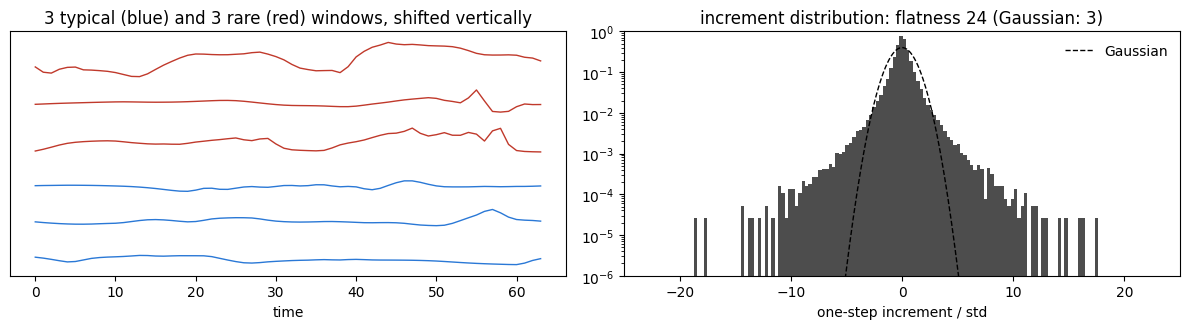

In [4]:
largest_jump = (data[..., 1:] - data[..., :-1]).abs().amax(dim=(1, 2))
is_rare = largest_jump > torch.quantile(largest_jump, 0.95)
typical_examples = torch.where(~is_rare)[0][:3]
rare_examples = torch.where(is_rare)[0][:3]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for i, j in enumerate(typical_examples):
    ax[0].plot(data[j, 0] + 4 * i, color='#2a78d6', lw=1)
for i, j in enumerate(rare_examples):
    ax[0].plot(data[j, 0] + 4 * (i + 3), color='#c0392b', lw=1)
ax[0].set_title('3 typical (blue) and 3 rare (red) windows, shifted vertically')
ax[0].set_xlabel('time'); ax[0].set_yticks([])

a = increments(data); a = (a / a.std()).numpy()
ax[1].hist(a, bins=120, density=True, log=True, color='0.3')
gauss_x = np.linspace(-8, 8, 200)
ax[1].plot(gauss_x, np.exp(-gauss_x ** 2 / 2) / np.sqrt(2 * np.pi), 'k--', lw=1, label='Gaussian')
ax[1].set_xlim(-25, 25); ax[1].set_ylim(1e-6, 1); ax[1].legend(frameon=False)
ax[1].set_xlabel('one-step increment / std')
ax[1].set_title(f'increment distribution: flatness {flatness(a):.0f} (Gaussian: 3)')
fig.tight_layout(); plt.show()

## 2. Do both methods generate correct samples?

The generated walkers at $t=1$ (5 runs pooled per case) against the data, on the statistic that matters most for
turbulence: the distribution of one-step increments, tails included.

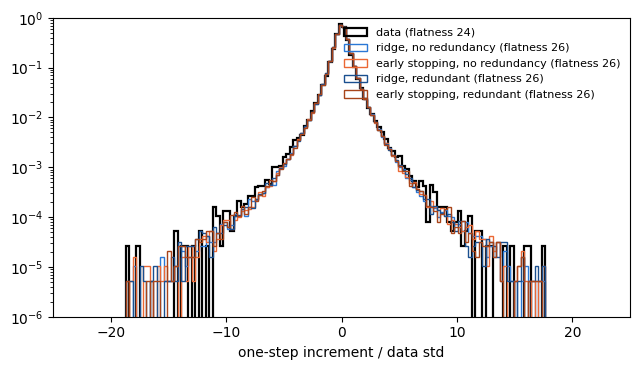

In [5]:
data_std = increments(data).std()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
a = (increments(data) / data_std).numpy()
ax.hist(a, bins=120, density=True, log=True, histtype='step', color='k', lw=1.6, label=f'data (flatness {flatness(a):.0f})')
for name in CASES:
    b = (increments(samples[name]) / data_std).numpy()
    ax.hist(b, bins=120, range=(a.min(), a.max()), density=True, log=True, histtype='step',
            color=COLORS[name], lw=1, label=f'{name} (flatness {flatness(b):.0f})')
ax.set_xlim(-25, 25); ax.set_ylim(1e-6, 1)
ax.set_xlabel('one-step increment / data std'); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## 3. Is the corrector stable along the run?

Left: $R_k$ = mean squared corrector displacement / mean squared random kick at step $k$, in units of the level expected
from finite-$N$ error alone ($r/(Nd)$). A numerical instability would appear as spikes or steady growth.
Right: how much of the mismatch the corrector leaves **unfitted along the nearly redundant directions**, in units of the
finite-$N$ error there (≈1: nothing systematic is left). Median over the 5 runs; dotted line: change of time step at $t=0.9$.

## $ R_k = \frac{\text{mean squared corrective push}}{\text{mean squared thermal kick}} = \frac{(h\sigma^2)^2\,\theta_k^\top\hat G\,\theta_k}{2h\sigma^2 d} \approx \frac{h\sigma^2\,\theta_t^\top G\,\theta_t}{2d} + \frac{r}{Nd}. $

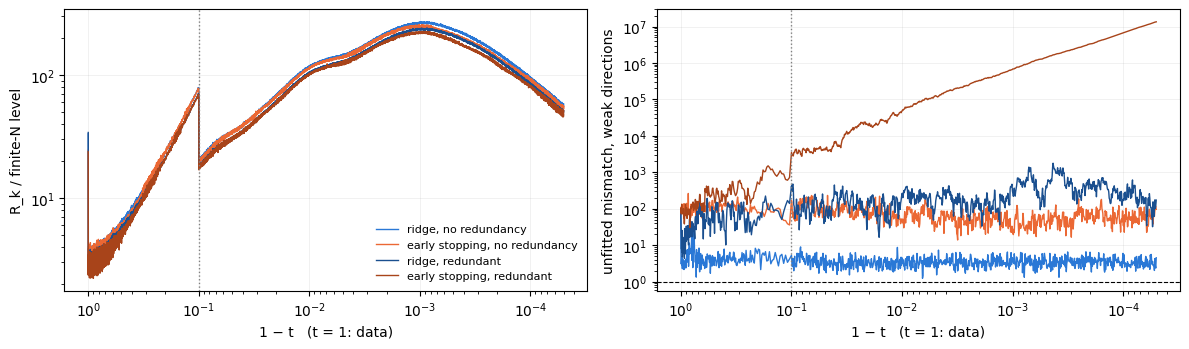

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name in CASES:
    runs = monitor[name]
    r = theta_reg[name].shape[1]                                           # number of statistics
    R = np.median([run['step'][:, 1].numpy() for run in runs], axis=0) / (r / (N_WALKERS * D))
    weak = np.median([np.nanmax(run['eig'][:, 5:].numpy(), axis=1) for run in runs], axis=0)
    weak_step = runs[0]['eig'][:, 0].numpy().astype(int)                   # steps where 'weak' was measured
    ax[0].plot(1 - t, R, color=COLORS[name], lw=1, label=name)
    ax[1].plot(1 - t[weak_step], weak, color=COLORS[name], lw=1, label=name)
for axis in ax:
    axis.set_xscale('log'); axis.set_yscale('log'); axis.invert_xaxis(); axis.grid(alpha=0.25, lw=0.5)
    axis.axvline(0.1, color='0.5', ls=':', lw=1); axis.set_xlabel('1 − t   (t = 1: data)')
ax[0].set_ylabel('R_k / finite-N level')
ax[1].set_ylabel('unfitted mismatch, weak directions'); ax[1].axhline(1, color='k', lw=0.8, ls='--')
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## 4. Is the learned model reproducible?

The decisive test for the estimated $\theta$: five independent runs on the **same data** should give the same model.
We compute $\log p_\theta(x)$ of every data window with each run's final $\Theta_{\rm reg}$ and compare runs pairwise
(correlation over the 2000 windows; the scatter shows run 900 vs run 901).

case                              corr median  worst pair   largest disagreement on one window (nats)
ridge, no redundancy                    1.000       1.000   23
early stopping, no redundancy           0.993       0.987   92
ridge, redundant                        1.000       0.999   25
early stopping, redundant               0.741       0.483   1482


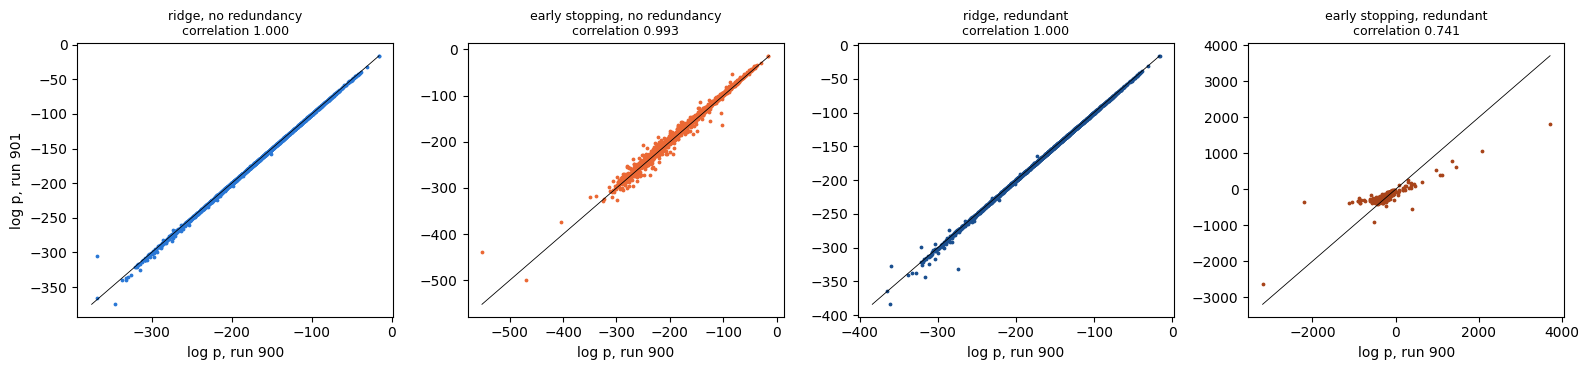

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
print(f"{'case':32s} {'corr median':>12s} {'worst pair':>11s}   largest disagreement on one window (nats)")
for i, name in enumerate(CASES):
    lp = log_p[name]
    corr = [np.corrcoef(lp[:, p], lp[:, q])[0, 1] for p in range(5) for q in range(p + 1, 5)]
    print(f'{name:32s} {np.median(corr):12.3f} {np.min(corr):11.3f}   {lp.std(axis=1).max():.0f}')
    ax[i].scatter(lp[:, 0], lp[:, 1], s=3, color=COLORS[name])
    lo, hi = lp[:, :2].min(), lp[:, :2].max()
    ax[i].plot([lo, hi], [lo, hi], 'k', lw=0.6)
    ax[i].set_title(f'{name}\ncorrelation {np.median(corr):.3f}', fontsize=9); ax[i].set_xlabel('log p, run 900')
ax[0].set_ylabel('log p, run 901')
fig.tight_layout(); plt.show()

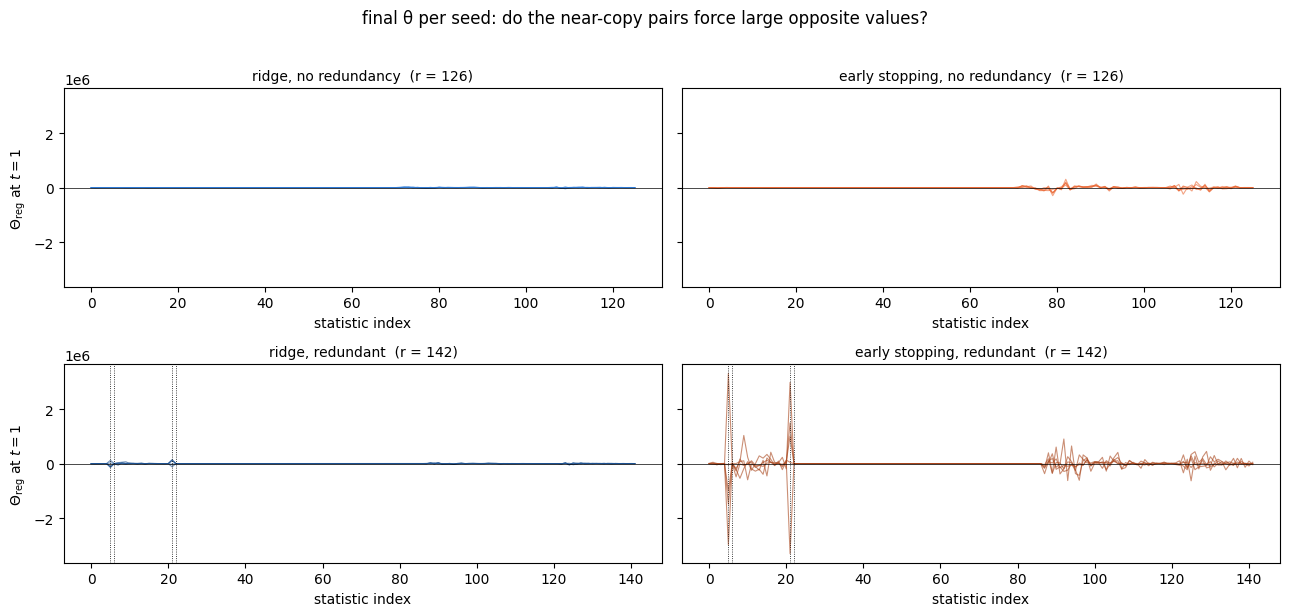

case                               col         theta (5 seeds, mean ± std)        sum of the pair
ridge, redundant                     5       -4.58e+04 ± 1.1e+05
                                    21       +4.57e+04 ± 1.1e+05  sum       -110 ± 1.4e+02
ridge, redundant                     6           +5.45 ± 4.9
                                    22           -5.45 ± 4.9  sum   -0.00448 ± 0.0048
early stopping, redundant            5       -4.43e+05 ± 2.4e+06
                                    21       +4.45e+05 ± 2.4e+06  sum  +1.28e+03 ± 3.6e+03
early stopping, redundant            6       +3.43e+03 ± 2e+03
                                    22       -3.43e+03 ± 2e+03  sum    +0.0353 ± 1.7


In [8]:
# compare theta: do redundant potentials force one method into large cancelling values?
# marks the near-copy pairs L_6[5]↔L_6_psi[14] and L_6[6]↔L_6_psi[15] (only present in the 'redundant' cases)

# column indices of L_6 and L_6_psi: start where each family starts in the stacked theta vector
# (depends on --terms order; this is the order used in the runs)
L6_START = 0
L6_LEN = 7
L6PSI_START = L6_LEN     # 7
# the two near-copy pairs: (L_6 column, L_6_psi column)
PAIRS = [(L6_START + 5, L6PSI_START + 14), (L6_START + 6, L6PSI_START + 15)]

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharey=True)
for ax, name in zip(axes.flatten(), CASES):
    Th = theta_reg[name].numpy()                 # (5 seeds, r)
    r = Th.shape[1]
    for s in range(5):
        ax.plot(Th[s], color=COLORS[name], lw=0.8, alpha=0.6)
    ax.axhline(0, color='k', lw=0.5)
    if 'redundant' in name:                      # mark the near-copy columns
        for a, b in PAIRS:
            ax.axvline(a, color='k', ls=':', lw=0.6)
            ax.axvline(b, color='k', ls=':', lw=0.6)
    ax.set_title(f'{name}  (r = {r})', fontsize=10)
    ax.set_xlabel('statistic index')
    #ax.set_yscale("symlog") 
axes[0, 0].set_ylabel(r'$\Theta_{\rm reg}$ at $t = 1$'); axes[1, 0].set_ylabel(r'$\Theta_{\rm reg}$ at $t = 1$')
fig.suptitle('final θ per seed: do the near-copy pairs force large opposite values?', y=1.02)
fig.tight_layout(); plt.show()

# numbers: size at the near-copy columns and size of their sum (what the data really sees)
print(f"{'case':32s} {'col':>5s} {'theta (5 seeds, mean ± std)':>35s} {'sum of the pair':>22s}")
for name in CASES:
    if 'redundant' not in name:
        continue
    Th = theta_reg[name]
    for a, b in PAIRS:
        pa, pb, ps = Th[:, a], Th[:, b], Th[:, a] + Th[:, b]
        print(f'{name:32s} {a:>5d} {pa.mean().item():+15.3g} ± {pa.std().item():.2g}')
        print(f'{"":32s} {b:>5d} {pb.mean().item():+15.3g} ± {pb.std().item():.2g}  sum {ps.mean().item():+10.3g} ± {ps.std().item():.2g}')

## Conclusion

- **Samples**: both methods generate samples of the same quality (same increment distribution, tails included), with or
  without redundant statistics; neither is numerically unstable ($R_k$ follows the same smooth curve in all four cases, no spikes or growth).
- **Model** ($\theta$, hence $\log p$): **ridge + $\Theta_{\rm reg}$ is reproducible** across runs and insensitive to the
  redundant statistics. **Early stopping is less reproducible** without redundancy and **fails with redundancy**: it
  leaves the nearly redundant directions uncorrected at every step (right panel of §3: growing steadily up to $\sim10^7$ times the finite-$N$ level);
  this leftover accumulates in the walkers, and $\Theta_{\rm reg}$, which re-fits the stored per-step data, converts it
  into large, run-dependent coefficients.
- **Choice**: ridge with a small fixed $\lambda$, followed by $\Theta_{\rm reg}$. The tuning-free early-stopping rule tested
  here does not remove the need to handle redundant statistics; ridge + $\Theta_{\rm reg}$ does.

*Scope*: one data set ($d=64$, 2000 windows), 5 runs per case, one ridge value ($10^{-4}$). The same conclusion holds in a
controlled Gaussian test with known truth (`krylov_stopping/RECAP_early_stopping.md`).